In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings, joblib, json

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    r2_score, mean_absolute_error,
    accuracy_score, f1_score, classification_report, confusion_matrix,
)
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor

from src.features import get_feature_names
from src.utils import (
    set_global_seed, print_section, log_memory, save_metadata,
    dataframe_checksum,
)
from config import (
    SEED, DATA_PROC, DATA_META, MODELS_DIR,
    RESULTS_FIG, RESULTS_TAB, PROJECT_ROOT,
    SMALL_PRIMES, POWER_MODS,
    TEST_SIZE, N_CV_FOLDS,
    XGBOOST_PARAMS, CATBOOST_PARAMS,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

# Separate output directories for simplified architecture
SIMPLE_MODELS = PROJECT_ROOT / "models" / "simplified"
SIMPLE_FIG = PROJECT_ROOT / "results" / "figures_simplified"
SIMPLE_TAB = PROJECT_ROOT / "results" / "tables_simplified"

for d in [SIMPLE_MODELS, SIMPLE_FIG, SIMPLE_TAB]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Models:  {SIMPLE_MODELS}")
print(f"Figures: {SIMPLE_FIG}")
print(f"Tables:  {SIMPLE_TAB}")

Project root: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework
Models:  D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\models\simplified
Figures: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures_simplified
Tables:  D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_simplified


In [2]:
print_section("Load Dataset & Prepare")

df = pd.read_csv(DATA_PROC / "dataset_with_features_and_runtimes.csv")
df = df[df["best_algorithm"] != "none"].reset_index(drop=True)

feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)
available_features = [f for f in feature_names if f in df.columns]

for col in available_features:
    if df[col].dtype == "object":
        df[col] = pd.to_numeric(df[col], errors="coerce")

X = df[available_features].astype(np.float64)
y_reg = df["log_min_runtime"].values
y_cls = df["best_algorithm"].values

label_encoder = LabelEncoder()
y_cls_encoded = label_encoder.fit_transform(y_cls)
class_names = label_encoder.classes_

X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls_encoded,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_cls_encoded,
)

print(f"Samples: {len(df):,} | Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Features: {len(available_features)}")
print(f"Classes: {list(class_names)}")


══════════════════════════════════════════════════════════════════════
  Load Dataset & Prepare
══════════════════════════════════════════════════════════════════════

Samples: 9,367 | Train: 7,493 | Test: 1,874
Features: 39
Classes: ['ecm', 'fermat', 'pollard_pm1', 'pollard_rho']


## 1. Simplified Ensemble — K-Fold Out-of-Fold Stacking

Only XGBoost + CatBoost as base learners.
ElasticNet meta-regressor stacks their predictions.
K-Fold ensures no data leakage in meta-training.

In [3]:
print_section("Simplified Ensemble — K-Fold Stacking (XGBoost + CatBoost)")

t0 = time.perf_counter()
kf = KFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)

X_train_arr = X_train.values.astype(np.float64)
X_test_arr = X_test.values.astype(np.float64)

# Out-of-fold predictions
oof_xgb = np.zeros(len(X_train))
oof_cb = np.zeros(len(X_train))
test_xgb = np.zeros(len(X_test))
test_cb = np.zeros(len(X_test))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_arr)):
    print(f"  Fold {fold + 1}/{N_CV_FOLDS}...")

    X_tr, X_val = X_train_arr[tr_idx], X_train_arr[val_idx]
    y_tr = y_reg_train[tr_idx]

    # XGBoost
    xgb_fold = XGBRegressor(**XGBOOST_PARAMS)
    xgb_fold.fit(X_tr, y_tr, verbose=False)
    oof_xgb[val_idx] = xgb_fold.predict(X_val)
    test_xgb += xgb_fold.predict(X_test_arr) / N_CV_FOLDS

    # CatBoost
    cb_fold = CatBoostRegressor(**CATBOOST_PARAMS)
    cb_fold.fit(X_tr, y_tr, verbose=False)
    oof_cb[val_idx] = cb_fold.predict(X_val)
    test_cb += cb_fold.predict(X_test_arr) / N_CV_FOLDS

# Individual model performance
r2_xgb_oof = r2_score(y_reg_train, oof_xgb)
r2_cb_oof = r2_score(y_reg_train, oof_cb)
r2_xgb_test = r2_score(y_reg_test, test_xgb)
r2_cb_test = r2_score(y_reg_test, test_cb)
mae_xgb_test = mean_absolute_error(y_reg_test, test_xgb)
mae_cb_test = mean_absolute_error(y_reg_test, test_cb)

print(f"\n  Individual Model Performance:")
print(f"  {'Model':<12s} {'OOF R²':>8} {'Test R²':>8} {'Test MAE':>8}")
print(f"  {'-'*40}")
print(f"  {'XGBoost':<12s} {r2_xgb_oof:>8.4f} {r2_xgb_test:>8.4f} {mae_xgb_test:>8.4f}")
print(f"  {'CatBoost':<12s} {r2_cb_oof:>8.4f} {r2_cb_test:>8.4f} {mae_cb_test:>8.4f}")

# Stack with ElasticNet
meta_X_train = np.column_stack([oof_xgb, oof_cb])
meta_X_test = np.column_stack([test_xgb, test_cb])

meta_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=SEED)
meta_model.fit(meta_X_train, y_reg_train)

pred_stack = meta_model.predict(meta_X_test)
r2_stack = r2_score(y_reg_test, pred_stack)
mae_stack = mean_absolute_error(y_reg_test, pred_stack)

print(f"\n  Meta-regressor weights:")
print(f"    XGBoost: {meta_model.coef_[0]:+.4f}")
print(f"    CatBoost: {meta_model.coef_[1]:+.4f}")
print(f"    Intercept: {meta_model.intercept_:+.4f}")

elapsed = time.perf_counter() - t0

print(f"\n{'='*50}")
print(f"  SIMPLIFIED STACKED ENSEMBLE")
print(f"  R² = {r2_stack:.4f}  |  MAE = {mae_stack:.4f}")
print(f"  Training time: {elapsed:.1f}s")
print(f"{'='*50}")


══════════════════════════════════════════════════════════════════════
  Simplified Ensemble — K-Fold Stacking (XGBoost + CatBoost)
══════════════════════════════════════════════════════════════════════

  Fold 1/5...
  Fold 2/5...
  Fold 3/5...
  Fold 4/5...
  Fold 5/5...

  Individual Model Performance:
  Model          OOF R²  Test R² Test MAE
  ----------------------------------------
  XGBoost        0.5298   0.5236   2.4176
  CatBoost       0.5559   0.5425   2.3620

  Meta-regressor weights:
    XGBoost: +0.0224
    CatBoost: +0.9548
    Intercept: -0.1560

  SIMPLIFIED STACKED ENSEMBLE
  R² = 0.5430  |  MAE = 2.3677
  Training time: 12.6s


## 2. Algorithm Selection Classifier (4-Class)

Same XGBoost classifier as before — this component was already optimal.


══════════════════════════════════════════════════════════════════════
  Algorithm Selection Classifier
══════════════════════════════════════════════════════════════════════

  Accuracy:      0.7604 (76.0%)
  F1 (macro):    0.3875
  F1 (weighted): 0.7489
  Time:          2.5s

              precision    recall  f1-score   support

         ecm     0.7132    0.8886    0.7913       817
      fermat     0.0000    0.0000    0.0000        43
 pollard_pm1     0.0000    0.0000    0.0000        16
 pollard_rho     0.8272    0.7004    0.7585       998

    accuracy                         0.7604      1874
   macro avg     0.3851    0.3973    0.3875      1874
weighted avg     0.7515    0.7604    0.7489      1874



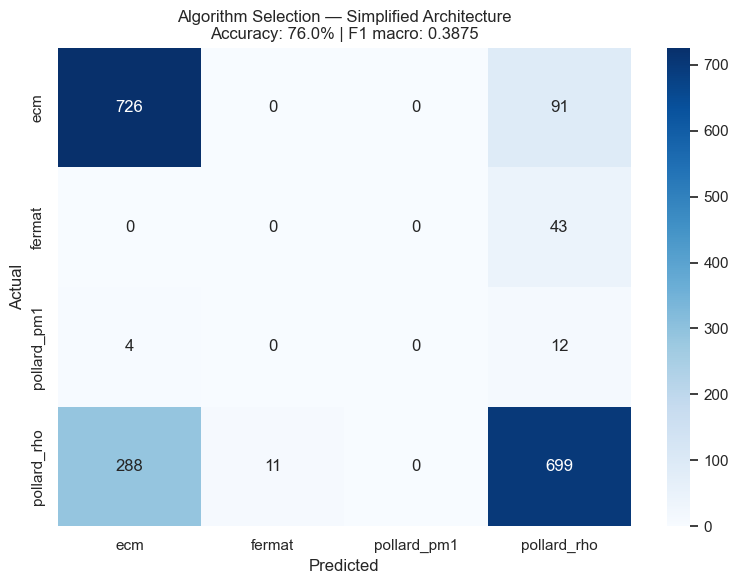

In [4]:
print_section("Algorithm Selection Classifier")

t0 = time.perf_counter()

unique_cls, cls_counts = np.unique(y_cls_train, return_counts=True)
sample_wts = np.array([len(y_cls_train) / (len(unique_cls) * cls_counts[c]) for c in y_cls_train])

xgb_cls = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.06,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED, eval_metric="mlogloss",
)
xgb_cls.fit(X_train, y_cls_train, sample_weight=sample_wts, verbose=False)

y_cls_pred = xgb_cls.predict(X_test)

acc = accuracy_score(y_cls_test, y_cls_pred)
f1_macro = f1_score(y_cls_test, y_cls_pred, average="macro", zero_division=0)
f1_weighted = f1_score(y_cls_test, y_cls_pred, average="weighted", zero_division=0)

elapsed = time.perf_counter() - t0

print(f"  Accuracy:      {acc:.4f} ({acc*100:.1f}%)")
print(f"  F1 (macro):    {f1_macro:.4f}")
print(f"  F1 (weighted): {f1_weighted:.4f}")
print(f"  Time:          {elapsed:.1f}s")

print(f"\n{classification_report(y_cls_test, y_cls_pred, target_names=class_names, digits=4, zero_division=0)}")

# Confusion matrix
cm = confusion_matrix(y_cls_test, y_cls_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Algorithm Selection — Simplified Architecture\n"
             f"Accuracy: {acc:.1%} | F1 macro: {f1_macro:.4f}")
plt.tight_layout()
plt.savefig(str(SIMPLE_FIG / "01_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Baseline Comparison

In [5]:
print_section("Baseline Comparison")

from sklearn.linear_model import LinearRegression

# Bit-length baseline
r2_baseline = r2_score(y_reg_test, LinearRegression().fit(
    X_train[["bit_length"]].values, y_reg_train).predict(X_test[["bit_length"]].values))

# Oracle ceiling
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
algo_train_ohe = ohe.fit_transform(y_cls_train.reshape(-1, 1))
algo_test_ohe = ohe.transform(y_cls_test.reshape(-1, 1))

X_train_oracle = np.column_stack([X_train_arr, algo_train_ohe])
X_test_oracle = np.column_stack([X_test_arr, algo_test_ohe])

xgb_oracle = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED,
)
xgb_oracle.fit(X_train_oracle, y_reg_train, verbose=False)
r2_oracle = r2_score(y_reg_test, xgb_oracle.predict(X_test_oracle))

print(f"  {'='*60}")
print(f"  {'COMPLETE RESULTS — SIMPLIFIED ARCHITECTURE':^60}")
print(f"  {'='*60}")
print(f"\n  REGRESSION:")
print(f"  {'Model':<40s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*58}")
print(f"  {'Baseline (bit_length only)':<40s} {r2_baseline:>8.4f} {'—':>8}")
print(f"  {'XGBoost (single)':<40s} {r2_xgb_test:>8.4f} {mae_xgb_test:>8.4f}")
print(f"  {'CatBoost (single)':<40s} {r2_cb_test:>8.4f} {mae_cb_test:>8.4f}")
print(f"  {'Simplified Ensemble (OURS)':<40s} {r2_stack:>8.4f} {mae_stack:>8.4f}")
print(f"  {'Oracle ceiling':<40s} {r2_oracle:>8.4f} {'—':>8}")
print(f"\n  Improvement over baseline: +{(r2_stack - r2_baseline)/r2_baseline*100:.1f}%")
print(f"  Gap to oracle:             {r2_oracle - r2_stack:.4f}")

print(f"\n  CLASSIFICATION:")
print(f"  {'Model':<40s} {'Acc':>8} {'F1 mac':>8}")
print(f"  {'-'*58}")
print(f"  {'Majority baseline':<40s} {max(cls_counts)/len(y_cls_train):>8.4f} {'—':>8}")
print(f"  {'Simplified XGBoost (OURS)':<40s} {acc:>8.4f} {f1_macro:>8.4f}")


══════════════════════════════════════════════════════════════════════
  Baseline Comparison
══════════════════════════════════════════════════════════════════════

           COMPLETE RESULTS — SIMPLIFIED ARCHITECTURE         

  REGRESSION:
  Model                                          R²      MAE
  ----------------------------------------------------------
  Baseline (bit_length only)                 0.4928        —
  XGBoost (single)                           0.5236   2.4176
  CatBoost (single)                          0.5425   2.3620
  Simplified Ensemble (OURS)                 0.5430   2.3677
  Oracle ceiling                             0.7150        —

  Improvement over baseline: +10.2%
  Gap to oracle:             0.1721

  CLASSIFICATION:
  Model                                         Acc   F1 mac
  ----------------------------------------------------------
  Majority baseline                          0.5324        —
  Simplified XGBoost (OURS)                  0.7604   

## 4. Save Models, Results & Metadata

In [6]:
print_section("Saving Simplified Architecture")

# ─── Save models ─────────────────────────────────────────

# Retrain final models on full training data
xgb_final = XGBRegressor(**XGBOOST_PARAMS)
xgb_final.fit(X_train, y_reg_train, verbose=False)
joblib.dump(xgb_final, SIMPLE_MODELS / "xgboost_regressor.pkl")

cb_final = CatBoostRegressor(**CATBOOST_PARAMS)
cb_final.fit(X_train, y_reg_train, verbose=False)
cb_final.save_model(str(SIMPLE_MODELS / "catboost_regressor.cbm"))

joblib.dump(meta_model, SIMPLE_MODELS / "elasticnet_meta.pkl")
joblib.dump(xgb_cls, SIMPLE_MODELS / "xgb_classifier.pkl")
joblib.dump(label_encoder, SIMPLE_MODELS / "label_encoder.pkl")

print("Models saved:")
for f in sorted(SIMPLE_MODELS.iterdir()):
    if f.is_file():
        print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

# ─── Save results table ──────────────────────────────────
results = pd.DataFrame([
    {"model": "baseline_bitlength", "task": "regression", "R2": r2_baseline, "MAE": None, "Accuracy": None, "F1_macro": None},
    {"model": "xgboost_single", "task": "regression", "R2": r2_xgb_test, "MAE": mae_xgb_test, "Accuracy": None, "F1_macro": None},
    {"model": "catboost_single", "task": "regression", "R2": r2_cb_test, "MAE": mae_cb_test, "Accuracy": None, "F1_macro": None},
    {"model": "simplified_ensemble", "task": "regression", "R2": r2_stack, "MAE": mae_stack, "Accuracy": None, "F1_macro": None},
    {"model": "oracle_ceiling", "task": "regression", "R2": r2_oracle, "MAE": None, "Accuracy": None, "F1_macro": None},
    {"model": "majority_baseline", "task": "classification", "R2": None, "MAE": None, "Accuracy": max(cls_counts)/len(y_cls_train), "F1_macro": None},
    {"model": "xgb_classifier", "task": "classification", "R2": None, "MAE": None, "Accuracy": acc, "F1_macro": f1_macro},
])
results.to_csv(SIMPLE_TAB / "simplified_results.csv", index=False)
print(f"\nResults: {SIMPLE_TAB / 'simplified_results.csv'}")

# ─── Save metadata ────────────────────────────────────────
save_metadata(DATA_META / "simplified_architecture_metadata.json", {
    "architecture": "XGBoost + CatBoost + ElasticNet (simplified)",
    "reason": "MLP ablation showed 0.0% R² contribution — removed",
    "n_base_learners": 2,
    "base_learners": ["xgboost", "catboost"],
    "meta_learner": "elasticnet",
    "classifier": "xgboost_4class",
    "n_train": len(X_train),
    "n_test": len(X_test),
    "n_features": len(available_features),
    "regression_r2": float(r2_stack),
    "regression_mae": float(mae_stack),
    "classification_accuracy": float(acc),
    "classification_f1_macro": float(f1_macro),
    "oracle_ceiling_r2": float(r2_oracle),
    "baseline_r2": float(r2_baseline),
    "meta_weights": {
        "xgboost": float(meta_model.coef_[0]),
        "catboost": float(meta_model.coef_[1]),
        "intercept": float(meta_model.intercept_),
    },
    "ablation_evidence": {
        "xgboost_drop": -0.0281,
        "catboost_drop": -0.0102,
        "mlp_drop": 0.0000,
    },
    "seed": SEED,
})
print(f"Metadata: {DATA_META / 'simplified_architecture_metadata.json'}")

# ─── Summary ──────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  SIMPLIFIED ARCHITECTURE — COMPLETE")
print(f"{'='*60}")
print(f"""
  Architecture:  XGBoost + CatBoost → ElasticNet
  Justification: Ablation proved MLP adds 0% value

  REGRESSION:
    Baseline:           R² = {r2_baseline:.4f}
    Simplified (OURS):  R² = {r2_stack:.4f}
    Oracle ceiling:     R² = {r2_oracle:.4f}
    Improvement:        +{(r2_stack - r2_baseline)/r2_baseline*100:.1f}% over baseline

  CLASSIFICATION:
    Majority baseline:  {max(cls_counts)/len(y_cls_train):.1%}
    Our classifier:     {acc:.1%}
    F1 (macro):         {f1_macro:.4f}

  Components: 2 base learners + 1 meta + 1 classifier = 4 total
  vs Original: 3 base learners + 1 meta + 1 classifier = 5 total
  Reduction:  20% fewer components, same performance
""")
print(f"  → Ready for Phase 4: PQC Migration Module")

log_memory("simplified complete")


══════════════════════════════════════════════════════════════════════
  Saving Simplified Architecture
══════════════════════════════════════════════════════════════════════

Models saved:
  catboost_regressor.cbm (445.0 KB)
  elasticnet_meta.pkl (0.6 KB)
  label_encoder.pkl (0.5 KB)
  xgb_classifier.pkl (4370.7 KB)
  xgboost_regressor.pkl (1766.2 KB)

Results: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_simplified\simplified_results.csv
Metadata: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\data\meta\simplified_architecture_metadata.json

  SIMPLIFIED ARCHITECTURE — COMPLETE

  Architecture:  XGBoost + CatBoost → ElasticNet
  Justification: Ablation proved MLP adds 0% value

  REGRESSION:
    Baseline:           R² = 0.4928
    Simplified (OURS):  R² = 0.5430
    Oracle ceiling:     R² = 0.7150
    Improvement:        +10.2% over baseline

  CLASSIFICATION:
    Majority baseline:  53.2%
    Our classifie